# Exercise 04b

In this exercise, you will use observations from Birmingham car parks to predict whether at least 80% of a car park's capacity is occupied.

The following cells display the raw data and divide the observations into training, validation, and test sets. Implement each network as an `nn.Module`, use a two-unit output layer and `nn.CrossEntropyLoss`, and assign the class with the larger output score.

You are responsible for choosing the network architecture and training settings. Questions 1 and 2 use validation performance for model selection. Question 3 evaluates the retained network once on the test set and compares it with several conventional classifiers.


## Open this notebook

- **Colab.** Replace `github.com` with `githubtocolab.com` in the repository URL, then open this file. Run the setup cell so Colab can see `parking_birmingham.csv`.
- **On your own computer.** Open this file from the `04 Artificial neural networks` folder, so `parking_birmingham.csv` sits beside the notebook.


In [1]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "04 Artificial neural networks"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    os.chdir(repo / LESSON_DIR)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/04 Artificial neural networks


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds the table, Matplotlib draws the figures, scikit-learn scales the columns and scores the predictions, and PyTorch builds the network.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("torch", torch.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
scikit-learn 1.7.2
torch 2.5.0
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After it finishes, restart the kernel and run the cells above again.


In [3]:
%pip install numpy pandas matplotlib scikit-learn torch torchinfo xgboost


Note: you may need to restart the kernel to use updated packages.


## The car parks

`parking_birmingham.csv` is Parking Birmingham, Stolfi (2017), UCI Machine Learning Repository, https://doi.org/10.24432/C51K5Z, shared under the UK Open Government Licence. Occupancy is used only to build the busy label. The inputs are the hour, the weekday, the capacity, and which car park it is.

The records are sorted by time. The first 50% of the dates are the training set, 4 October 2016 through 10 November 2016. The next 25% are the validation set, 11 November through 28 November. The last 25% are the test set, 29 November through 19 December. Every car park observed on one date stays in the same set. Car park `BHMBRTARC01` appears only from 13 to 18 December, inside the test set, so it has no column. Those rows are 0 on every car-park column.

`StandardScaler` is fit on the training rows only. `X_train`, `X_valid`, and `X_test` are the PyTorch tensors. The `*_np` arrays are the same numbers, for a scikit-learn model later. `shuffle=True` in a training loader mixes only the training rows.


## What the rows look like

The next cell prints the first rows, then how full the car parks are. The dashed line is 0.8. Rows on or above that line are busy. The bar on the right counts the two groups. Busy is the shorter bar, about one row in six.


rows 35717
columns ['SystemCodeNumber', 'Capacity', 'Occupancy', 'LastUpdated']
  SystemCodeNumber  Capacity  Occupancy          LastUpdated
0      BHMBCCMKT01       577         61  2016-10-04 07:59:42
1      BHMBCCMKT01       577         64  2016-10-04 08:25:42
2      BHMBCCMKT01       577         80  2016-10-04 08:59:42
3      BHMBCCMKT01       577        107  2016-10-04 09:32:46
4      BHMBCCMKT01       577        150  2016-10-04 09:59:48
car parks 30
       Capacity  Occupancy      rate
count  35717.00   35717.00  35717.00
mean    1397.55     642.23      0.49
std     1179.33     656.96      0.27
min      220.00      -8.00     -0.02
25%      500.00     210.00      0.26
50%      849.00     446.00      0.47
75%     2009.00     798.00      0.72
max     4675.00    4327.00      1.04
busy
not busy    29643
busy         6074


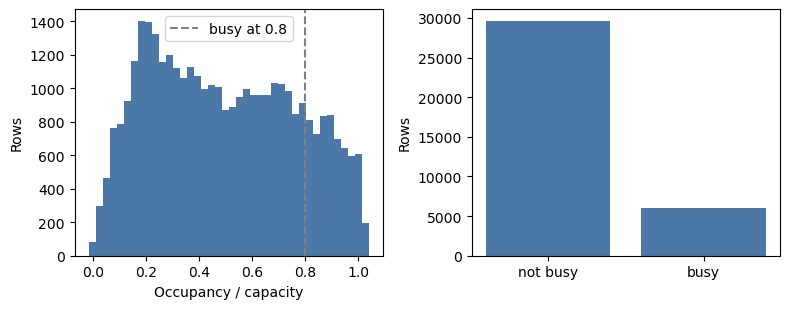

In [4]:
park = pd.read_csv("parking_birmingham.csv")
print("rows", len(park))
print("columns", list(park.columns))
print(park.head().to_string())
print("car parks", park["SystemCodeNumber"].nunique())

park["time"] = pd.to_datetime(park["LastUpdated"])
park["hour"] = park["time"].dt.hour
park["rate"] = park["Occupancy"] / park["Capacity"]
park["busy"] = (park["rate"] >= 0.8).astype(int)
print(park[["Capacity", "Occupancy", "rate"]].describe().round(2).to_string())
print(park["busy"].value_counts().rename({0: "not busy", 1: "busy"}).to_string())

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
axes[0].hist(park["rate"], bins=40, color="#4C78A8")
axes[0].axvline(0.8, color="gray", linestyle="--", label="busy at 0.8")
axes[0].set_xlabel("Occupancy / capacity")
axes[0].set_ylabel("Rows")
axes[0].legend()
counts = park["busy"].value_counts().sort_index()
axes[1].bar(["not busy", "busy"], [int(counts.get(0, 0)), int(counts.get(1, 0))], color="#4C78A8")
axes[1].set_ylabel("Rows")
fig.tight_layout()
plt.show()


In [5]:
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler

park = pd.read_csv("parking_birmingham.csv")
park["time"] = pd.to_datetime(park["LastUpdated"])
park["day"] = park["time"].dt.normalize()
park["hour"] = park["time"].dt.hour
park["weekday"] = park["time"].dt.weekday
park["busy"] = (park["Occupancy"] / park["Capacity"] >= 0.8).astype(int)
park = park.sort_values(["time", "SystemCodeNumber"]).reset_index(drop=True)
days = park["day"].drop_duplicates().tolist()
n_days = len(days)
train_days = days[: int(n_days * 0.50)]
valid_days = days[int(n_days * 0.50) : int(n_days * 0.75)]
test_days = days[int(n_days * 0.75) :]
train = park[park["day"].isin(train_days)].copy()
valid = park[park["day"].isin(valid_days)].copy()
test = park[park["day"].isin(test_days)].copy()
print("training days", train_days[0].date(), "to", train_days[-1].date(), len(train_days))
print("validation days", valid_days[0].date(), "to", valid_days[-1].date(), len(valid_days))
print("test days", test_days[0].date(), "to", test_days[-1].date(), len(test_days))

num = ["hour", "weekday", "Capacity"]
cat = ["SystemCodeNumber"]
X_train_np = pd.concat([train[num].astype(float), pd.get_dummies(train[cat], dtype=int)], axis=1)
X_valid_np = pd.concat([valid[num].astype(float), pd.get_dummies(valid[cat], dtype=int)], axis=1)
X_test_np = pd.concat([test[num].astype(float), pd.get_dummies(test[cat], dtype=int)], axis=1)
X_valid_np = X_valid_np.reindex(columns=X_train_np.columns, fill_value=0)
X_test_np = X_test_np.reindex(columns=X_train_np.columns, fill_value=0)

scaler = StandardScaler()
X_train_np = scaler.fit_transform(X_train_np).astype("float32")
X_valid_np = scaler.transform(X_valid_np).astype("float32")
X_test_np = scaler.transform(X_test_np).astype("float32")
y_train_np = train["busy"].to_numpy()
y_valid_np = valid["busy"].to_numpy()
y_test_np = test["busy"].to_numpy()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_train = torch.tensor(X_train_np, dtype=torch.float32).to(device)
X_valid = torch.tensor(X_valid_np, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test_np, dtype=torch.float32).to(device)
y_train = torch.tensor(y_train_np, dtype=torch.long).to(device)
y_valid = torch.tensor(y_valid_np, dtype=torch.long).to(device)
y_test = torch.tensor(y_test_np, dtype=torch.long).to(device)

print("rows", len(train), len(valid), len(test))
print("input columns", X_train_np.shape[1])
print("share busy, train", round(float(y_train_np.mean()), 2))

print("Input and target shapes")
print("X_train:", tuple(X_train.shape), "y_train:", tuple(y_train.shape))
print("X_valid:", tuple(X_valid.shape), "y_valid:", tuple(y_valid.shape))
print("X_test: ", tuple(X_test.shape), "y_test: ", tuple(y_test.shape))



training days 2016-10-04 to 2016-11-10 36
validation days 2016-11-11 to 2016-11-28 18
test days 2016-11-29 to 2016-12-19 19
rows 17496 8964 9257
input columns 32
share busy, train 0.14


### Question 1 — compare network architectures

Build a reusable training function and compare at least eight architectures, including one-hidden-layer and two-hidden-layer networks. Keep ReLU, Adam, learning rate `0.001`, and 40 epochs fixed so that the architecture is the only changing factor.

Report validation precision, recall, F1, and AUC for the busy class. Plot validation F1 against architecture and retain the architecture with the highest validation F1. Do not use the test set.

### Question 2 — tune activation, optimisation, and decision threshold

Using the architecture retained in Question 1:

1. Compare Sigmoid, Tanh, ReLU, and Leaky ReLU in a one-dimensional experiment.
2. For the best activation, evaluate **every learning-rate–weight-decay combination**. A suitable grid is learning rates `0.0003`, `0.001`, `0.003`, `0.01`, `0.03`, and `0.05`, crossed with weight decay `0`, `0.00001`, `0.0001`, `0.001`, and `0.01`. Display the validation F1 values in a table and a two-dimensional heatmap.
3. Plot training and validation loss for the selected setting.
4. The network outputs a probability. On the validation set only, compare several probability thresholds and plot F1 against threshold. Retain the threshold with the highest validation F1.

Do not inspect the test set until all four settings—architecture, activation, optimiser parameters, and threshold—are frozen.

### Question 3 — compare the frozen ANN with other classifiers

Tune the following models on the validation set:

- logistic regression over several values of `C`;
- a decision tree over `max_depth × min_samples_leaf`;
- a random forest over `max_depth × min_samples_leaf`;
- XGBoost over `max_depth × learning_rate`; and
- a linear SVM over several values of `C`.

Use one-dimensional curves and two-dimensional heatmaps to show the validation searches. After freezing every model, evaluate each model once on the test set. Report precision, recall, F1, and AUC; draw the ROC curves and confusion matrices; and explain which model is preferable when missing a busy car park is more costly than a false alarm.